# Data Mining - Project

### Work done by
- Roberto Rolão de Castro 107133
- Tiago Caridade Gomes 108307

## Tracking the Evolution of E-commerce Websites in Portugal

### Description
Study how e-commerce websites in Portugal, such as those related to retail (e.g., Worten, Fnac), have changed in terms of offerings and product availability.

### Data
Gather versions of popular e-commerce sites over time from Arquivo.pt.

---

## Project Objectives

The main objectives of this project are:
- To understand the evolution of e-commerce websites in Portugal.
- To analyze changes in product availability, pricing, and diversity over time.

## State of the Art / Similar Works

Research on tracking changes in online content using web archives has been supported by the Arquivo.pt awards, which recognize innovative use cases involving archived web data. Some of these award-winning projects have tackled challenges similar to ours:

- **2024 Arquivo.pt Award Winners**: Projects that focused on extracting and analyzing data from Portuguese web archives to gain insights into historical trends in different domains. More details can be found [here](https://sobre.arquivo.pt/en/meet-the-winners-of-the-arquivo-pt-award-2024/).
  
- **2021 Arquivo.pt Award Winners**: Notable works from this year included analyses that utilized web archives for various purposes, including monitoring the evolution of online information. More details [here](https://sobre.arquivo.pt/en/meet-the-winners-of-the-arquivo-pt-award-2021/).

- **2020 Arquivo.pt Award Winners**: Projects from 2020 included using the Arquivo.pt for research on Portuguese historical data, similar to our interest in studying the evolution of e-commerce websites. More information [here](https://sobre.arquivo.pt/en/meet-the-winners-of-the-arquivo-pt-award-2020/).

These works demonstrate the versatility of using web archives like Arquivo.pt for historical analysis of online content, providing a foundation and inspiration for our project.

## Data Acquisition

The data was gathered using the [Arquivo.pt](https://arquivo.pt/) API to fetch archived versions of websites related to retail and technology products. We defined a set of keywords and a list of URLs for popular e-commerce sites.

**Methodology:**
- Defined search terms related to specific product categories (e.g., electronics, appliances).
- Selected major e-commerce platforms in Portugal (e.g., Worten, Fnac, Radio Popular).
- Implemented a script to iteratively request data from the Arquivo.pt API while handling pagination.

**Challenges:**
- **Pagination Limitations**: The API has limitations on how much data can be fetched at once. This was overcome by implementing a custom pagination strategy to ensure all data was retrieved.
- **Duplicate URLs**: To avoid redundant data, a mechanism was implemented to track already processed URLs.


## Implementation

Below is an overview of the Python code used to gather the data from Arquivo.pt. The code is divided into functions for reading input URLs, fetching data from the API, and processing the results. All code is commented to ensure clarity.

#### Query definition and methodology for organizing/saving data

---

In [1]:
import requests
import pandas as pd
import os
from bs4 import BeautifulSoup
import re

def read_list_from_file(filename):
    """
    Reads a list of items from a file, one item per line.
    :param filename: The name of the file to read from.
    :return: A list of strings, each representing an item from the file.
    """
    with open(filename, 'r') as file:
        return [line.strip() for line in file if line.strip()]  # Read non-empty lines and remove whitespace

def fetch_all_results(websites, keywords):
    """
    Fetch all results from Arquivo.pt for the given websites and keywords.
    :param websites: List of websites to search.
    :param keywords: List of keywords to use in the search.
    """
    # Base URL for Arquivo.pt text search API
    url = "https://arquivo.pt/textsearch"
    all_data = []  # List to store data fetched from the API
    seen_urls = set()  # Set to track URLs that have already been added to avoid duplicates

    # Ensure the "Results" directory exists to save output files
    os.makedirs('./Results', exist_ok=True)

    # Iterate over each website and keyword combination
    for website in websites:
        for keyword in keywords:
            print(f"Starting search for '{keyword}' on {website}")
            # Define the parameters for the API request
            base_params = {
                "from": "20100101000000",  # Start date for the search (YYYYMMDDHHMMSS format)
                "to": "20200101000000",    # End date for the search (YYYYMMDDHHMMSS format)
                "maxItems": 500,            # Maximum number of items per request
                "q": keyword,               # Keyword to search for
                "siteSearch": website,      # Website to restrict the search to
                "dedupValue": 0,            # Disable deduplication by value
                "dedupField": "url",       # Field used for deduplication
                "offset": 0                 # Offset for pagination
            }

            # Fetch data for each combination of website and keyword
            while True:
                try:
                    # Make a GET request to the API with the defined parameters
                    response = requests.get(url, params=base_params)
                    response.raise_for_status()  # Raise an error for bad status codes
                except requests.exceptions.RequestException as e:
                    # Handle any request exceptions (e.g., connection issues, timeouts)
                    print(f"Error fetching data at offset {base_params['offset']}: {e}")
                    break

                # Parse the response JSON
                data = response.json()
                if 'response_items' in data and data['response_items']:
                    # Convert the response items to a DataFrame
                    current_data = pd.DataFrame(data['response_items'])

                    # Filter out duplicate URLs based on 'linkToExtractedText'
                    new_data = current_data[~current_data['linkToExtractedText'].isin(seen_urls)]
                    if not new_data.empty:
                        all_data.append(new_data)  # Append new data to the list
                        # Add the new URLs to the seen set to avoid duplicates
                        seen_urls.update(new_data['linkToExtractedText'])
                        print(f"Added {len(new_data)} new items for '{keyword}' on {website} at offset {base_params['offset']}")
                    else:
                        print(f"No new items found for '{keyword}' on {website} at offset {base_params['offset']}")

                    # If fewer results were returned than maxItems, it means we reached the last page
                    if len(current_data) < base_params['maxItems']:
                        print("Reached the last page of data.")
                        break

                    # Increment the offset to fetch the next batch of results
                    base_params['offset'] += base_params['maxItems']
                else:
                    # No more data available or reached API limit
                    print("No more data available or reached API limit.")
                    break

            # Save the results for the current website and keyword
            if all_data:
                # Concatenate all data frames into one final DataFrame
                final_data = pd.concat(all_data, ignore_index=True)
                
                # Drop duplicates from the final DataFrame based on 'linkToExtractedText'
                final_data = final_data.drop_duplicates(subset=['linkToExtractedText'])

                # Define the output filename based on the website and keyword
                output_filename = f"./Results/{website.replace('https://', '').replace('.', '_')}_{keyword}.csv"
                # Save the DataFrame to a CSV file
                final_data.to_csv(output_filename, index=False)
                print(f"Data saved to {output_filename}")
                all_data.clear()  # Clear the list for the next combination
            else:
                print(f"No data found for '{keyword}' on {website}")

def main():
    # Read websites and keywords from files
    websites = read_list_from_file('websites.txt')  # List of websites to search
    keywords = read_list_from_file('categories.txt')  # List of keywords to search for

    # Fetch all results based on the websites and keywords
    fetch_all_results(websites, keywords)

if __name__ == "__main__":
    main()  # Run the main function


Starting search for 'Telemóvel' on https://www.worten.pt
Added 500 new items for 'Telemóvel' on https://www.worten.pt at offset 0
Added 500 new items for 'Telemóvel' on https://www.worten.pt at offset 500
Added 500 new items for 'Telemóvel' on https://www.worten.pt at offset 1000
Added 500 new items for 'Telemóvel' on https://www.worten.pt at offset 1500
No more data available or reached API limit.
Data saved to ./Results/www_worten_pt_Telemóvel.csv
Starting search for 'Smartphone' on https://www.worten.pt
Added 432 new items for 'Smartphone' on https://www.worten.pt at offset 0
Added 494 new items for 'Smartphone' on https://www.worten.pt at offset 500
Added 459 new items for 'Smartphone' on https://www.worten.pt at offset 1000
Added 288 new items for 'Smartphone' on https://www.worten.pt at offset 1500
No more data available or reached API limit.
Data saved to ./Results/www_worten_pt_Smartphone.csv
Starting search for 'Portátil' on https://www.worten.pt
Added 493 new items for 'Portá

## WEB Scrapping

#### Overview

This script automates web scraping for product data stored in archived CSV files. It retrieves product titles and prices from various e-commerce websites using BeautifulSoup. The script processes saved files and extracts relevant information for analysis. The processed data is saved into new CSV files.

---

In [ ]:
import pandas as pd
import os
from bs4 import BeautifulSoup
import requests
import re


def web_scrape(title_classes, price_classes, soup):
    """
    Scrapes product title and price from a webpage.

    Args:
        title_classes (list): List of possible CSS class names for product titles.
        price_classes (list): List of possible CSS class names for product prices.
        soup (BeautifulSoup): Parsed HTML content of the webpage.

    Returns:
        tuple: Product title and price as strings.
    """

    # Iterate over potential CSS classes to find the product title
    product_title = "N/A"
    for title_class in title_classes:
        title_element = soup.find(class_=title_class)
        if title_element:
            product_title = title_element.get_text(strip=True)
            break

    # Iterate over potential CSS classes to find the product price
    price = "N/A"
    for price_class in price_classes:
        price_element = soup.find(class_=price_class)
        if price_element:
            price = price_element.get_text(strip=True)
            break

    print(f"Product Title: {product_title}")
    print(f"Product Price: {price}")

    return product_title, price

def isValidData(product_title, price):
    """
    Validates the extracted product title and price.

    Args:
        product_title (str): The product title.
        price (str): The product price.

    Returns:
        bool: True if both title and price are valid, False otherwise.
    """

    # Check if the product title or price is "N/A" or if the title contains "Substituição"
    if product_title == "N/A" or "Substituição" in product_title or price == "N/A":
        return False
    return True


def scrape_saved_files(results_dir):
    """
    Scrapes product data from archived CSV files and saves the results.

    Args:
        results_dir (str): Path to the directory containing input CSV files.
    """

    scraped_data = []
    if not os.path.exists('./Scraped_Results'):
        os.makedirs('./Scraped_Results')

    # Iterate over all files in the specified directory
    for file_name in os.listdir(results_dir):
        if file_name.endswith('.csv'):
                
            file_path = os.path.join(results_dir, file_name)
            print(f"Scraping data from file: {file_path}")
            df = pd.read_csv(file_path)

            # Process each row in the CSV file
            for _, row in df.iterrows():
                archive_url = row.get("linkToNoFrame")
                if archive_url:
                    try:
                        print("----------------------------")
                        print(f"Scraping data from: {archive_url}")

                        # Fetch webpage content
                        page = requests.get(archive_url)
                        soup = BeautifulSoup(page.content, 'html.parser')

                        product_title = "N/A"
                        price = "N/A"
                        
                        # Fetch webpage content
                        site = re.split(r'[_\.]', file_name)
                        if site[0] == 'www':
                            site.remove('www')

                        # Scraping logic for specific websites
                        if 'worten' in site[0]:

                            # List of possible classes for title and price
                            title_classes = ['h1', 'w-product__name', 'w-product__title']
                            price_classes = ['w-product-price__main', 'w-currentPrice', 'main_price']

                            product_title, price = web_scrape(title_classes, price_classes, soup)

                            if isValidData(product_title, price) == False:
                                print(f"Skipping invalid product page: {archive_url}")
                                continue
                        
                        if 'fnac' in site[0]:
                            
                            # List of possible classes for title and price
                            title_classes = ['f-productHeader-Title', 'Article-desc']
                            price_classes = ['f-priceBox-price', 'userPrice', 'pictoProduitNormal']

                            product_title, price = web_scrape(title_classes, price_classes, soup)

                            if product_title == "N/A" or "Substituição" in product_title or price == "N/A":
                                print(f"Skipping invalid product page: {archive_url}")
                                continue

                        if 'radiopopular' in site[0]:
                            
                            # List of possible classes for title and price
                            title_classes = ['designation fl', 'texto7 sombra1 grande altura8 espacamento8 topo']
                            price_classes = ['price notranslate', 'tamanho9']
                            
                            product_title, price = web_scrape(title_classes, price_classes, soup)

                            if isValidData(product_title, price) == False:
                                print(f"Skipping invalid product page: {archive_url}")
                                continue


                        if 'mediamarkt' in site[0]:

                            # Handle title manually for MediaMarkt
                            h1_element = soup.find("h1", itemprop="name")
                            product_title = h1_element.get_text(strip=True) if h1_element else "N/A"

                            # List of possible classes for price
                            price_classes = ['price clearfix']

                            # Use the existing function for price scraping
                            _, price = web_scrape([], price_classes, soup)
                        
                            
                            if isValidData(product_title, price) == False:
                                print(f"Skipping invalid product page: {archive_url}")
                                continue

                        if 'kuantokusta' in site[0]:
                            
                            # List of possible classes for title and price
                            title_classes = ['product-title']
                            price_classes = ['price', 'need-go product-price']

                            product_title, price = web_scrape(title_classes, price_classes, soup)

                            if isValidData(product_title, price) == False:
                                print(f"Skipping invalid product page: {archive_url}")
                                continue

                        if 'elcorteingles' in site[0]:
                            
                            # List of possible classes for title and price
                            title_classes = ['title', 'h2', 'js-product-click event', 'listado_texto']
                            price_classes = ['current sale', 'price', 'current', 'listado_precio_normal', 'precio_normal']

                            product_title, price = web_scrape(title_classes, price_classes, soup)

                            if isValidData(product_title, price) == False:
                                print(f"Skipping invalid product page: {archive_url}")
                                continue

                        
                        if 'pcdiga' in site[0]:
                            
                            # List of possible classes for title and price
                            title_classes = ['product-card--title']
                            price_classes = ['price']

                            product_title, price = web_scrape(title_classes, price_classes, soup)

                            if isValidData(product_title, price) == False:
                                print(f"Skipping invalid product page: {archive_url}")
                                continue
                        
                        # Append valid scraped data to the list
                        scraped_data.append({
                            "title": product_title,
                            "price": price,
                            "category": site[2],
                            "timestamp": row.get("tstamp"),
                            "website": site[0],
                            "linkToNoFrame": row.get("linkToNoFrame")
                        })

                        print("----------------------------\n\n")
                        
                    except Exception as e:
                        print(f"Error scraping {archive_url}: {e}")
                        continue

            # Save scraped data to a new CSV
            if scraped_data:
                scraped_df = pd.DataFrame(scraped_data)
                scraped_output_file = f"./Scraped_Results/scraped_{file_name}"
                scraped_df.to_csv(scraped_output_file, index=False)
                print(f"Scraped data saved to {scraped_output_file}")
                scraped_data.clear()


def main():
    scrape_saved_files('./Results')

if __name__ == "__main__":
    main()  # Run the main function

## Cleaning Treatment

#### Overview

This script processes scraped data from CSV files, cleaning and correcting the data for further use. The key tasks performed by the script are __Removing Invalid Entries__, __Cleaning Price Data__, __Ensuring Valid Data__ and __Saving Cleaned Data__.

---

In [4]:
import os
import pandas as pd
import re

# Function to correct improperly formatted prices (e.g., "1.129.99" -> "1129.99")
def correct_price_format(price):
    """
    Corrects improperly formatted price strings.
    :param price: The price string to correct
    :return: The corrected price string
    """
    
    # Regex pattern to identify incorrect formats (e.g., "1.129.99")
    pattern = r"\b(\d)\.(\d{3})\.(\d{2})\b"

    # Replace incorrect format with the correct one (e.g., "1129.99")
    corrected_price = re.sub(pattern, r"\1\2.\3", price)
    return corrected_price


def clean_data(directory):
    """
    Cleans the scraped data by removing invalid entries and formatting prices.
    :param directory: The directory containing the scraped CSV files
    """

    # Iterate over all files in the directory
    for file_name in os.listdir(directory):
        if file_name.startswith('scraped_') and file_name.endswith('.csv'):
            file_path = os.path.join(directory, file_name)
            print(f"Cleaning data in file: {file_path}")
            df = pd.read_csv(file_path)

            # Remove rows where the 'price' column contains specific invalid values
            df = df[df['price'] != "Mostrar quatro produtos por fila"]

            # Clean and format the 'price' column
            df['price'] = (
                df['price']
                .astype(str)  # Ensure all values in 'price' are strings
                .str.replace(r'\xa0', '', regex=True)  # Remove non-breaking spaces
                .str.replace(r'[^\d.,]', '', regex=True)  # Remove non-numeric characters
                .replace(',', '.', regex=True)  # Replace commas with dots
                .apply(correct_price_format)  # Correct improperly formatted prices
            )

            # Remover linhas onde o preço está vazio
            df = df[df['price'] != '']
            df = df[df['price'].notna()]  # Garantir que não há NaN


            # Save the cleaned data back to the file
            df.to_csv(file_path, index=False)
            print(f"Cleaned data saved to {file_path}")


def main():
    clean_data('./Scraped_Results')

if __name__ == "__main__":
    main()  # Run the main function

Cleaning data in file: ./Scraped_Results/scraped_www_radiopopular_pt_Smartphone.csv
Cleaned data saved to ./Scraped_Results/scraped_www_radiopopular_pt_Smartphone.csv
Cleaning data in file: ./Scraped_Results/scraped_www_radiopopular_pt_Computadores.csv
Cleaned data saved to ./Scraped_Results/scraped_www_radiopopular_pt_Computadores.csv
Cleaning data in file: ./Scraped_Results/scraped_www_elcorteingles_pt_Telemóvel.csv
Cleaned data saved to ./Scraped_Results/scraped_www_elcorteingles_pt_Telemóvel.csv
Cleaning data in file: ./Scraped_Results/scraped_www_pcdiga_com_Portáteis.csv
Cleaned data saved to ./Scraped_Results/scraped_www_pcdiga_com_Portáteis.csv
Cleaning data in file: ./Scraped_Results/scraped_www_elcorteingles_pt_Computador.csv
Cleaned data saved to ./Scraped_Results/scraped_www_elcorteingles_pt_Computador.csv
Cleaning data in file: ./Scraped_Results/scraped_www_kuantokusta_pt_Portáteis.csv
Cleaned data saved to ./Scraped_Results/scraped_www_kuantokusta_pt_Portáteis.csv
Cleaning

## Visualizations

#### Overview

This script is designed to process CSV files containing product price data, categorize the data by product categories, and generate detailed visualizations (line plots) for each category showing the price evolution over time.

---

/var/folders/yk/6y9yrkbx0778n8h565f9bj4w0000gn/T/ipykernel_61845/1301377773.py:39: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("tab20")  # Improved color palette


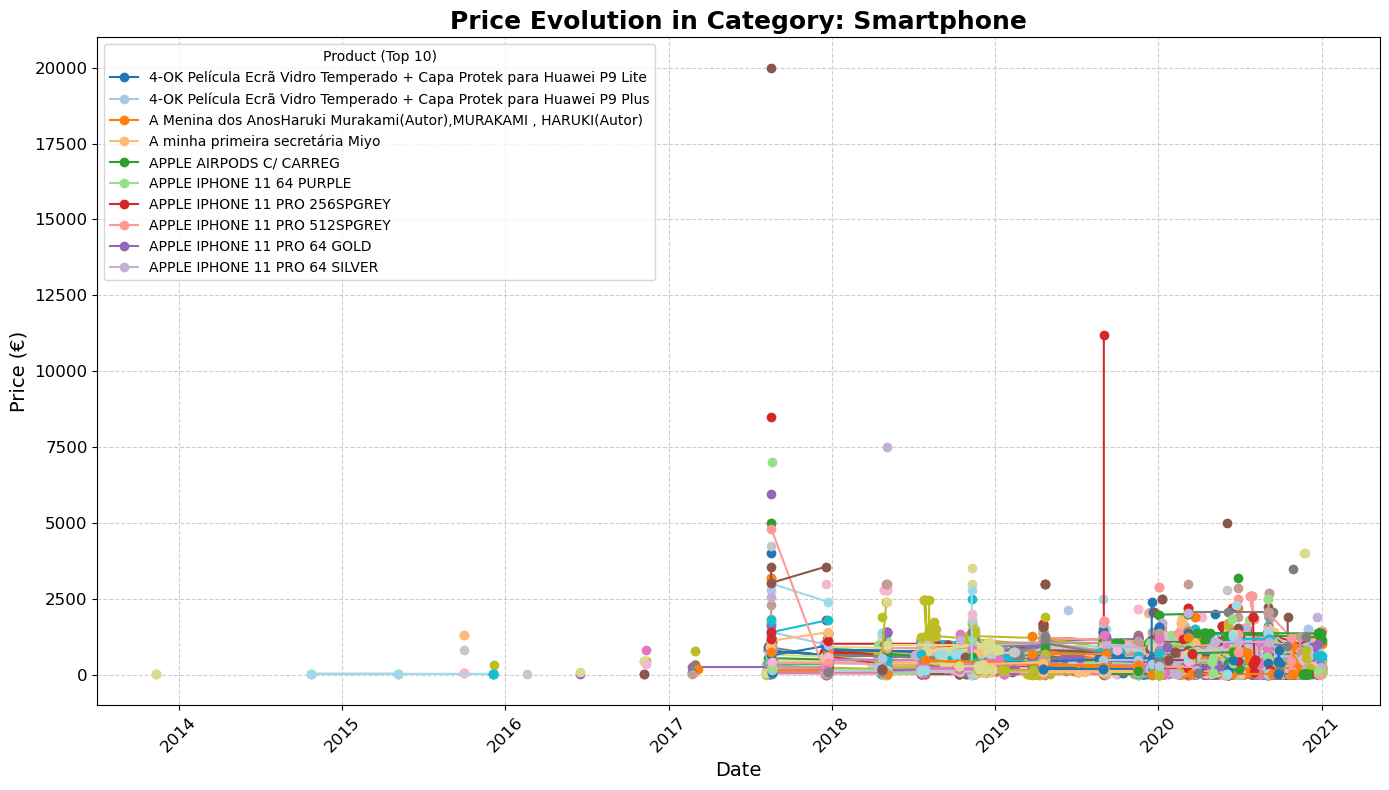

/var/folders/yk/6y9yrkbx0778n8h565f9bj4w0000gn/T/ipykernel_61845/1301377773.py:39: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("tab20")  # Improved color palette


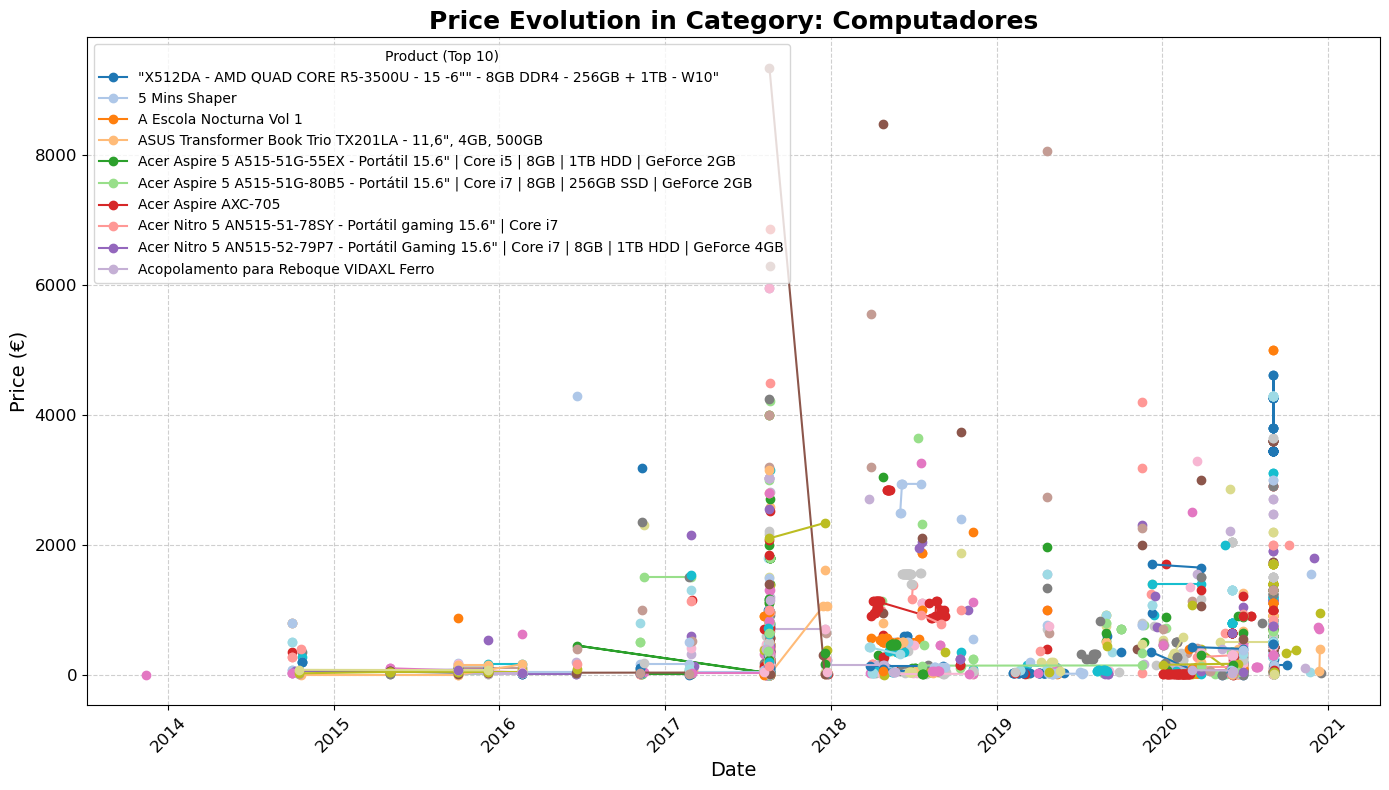

/var/folders/yk/6y9yrkbx0778n8h565f9bj4w0000gn/T/ipykernel_61845/1301377773.py:39: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("tab20")  # Improved color palette


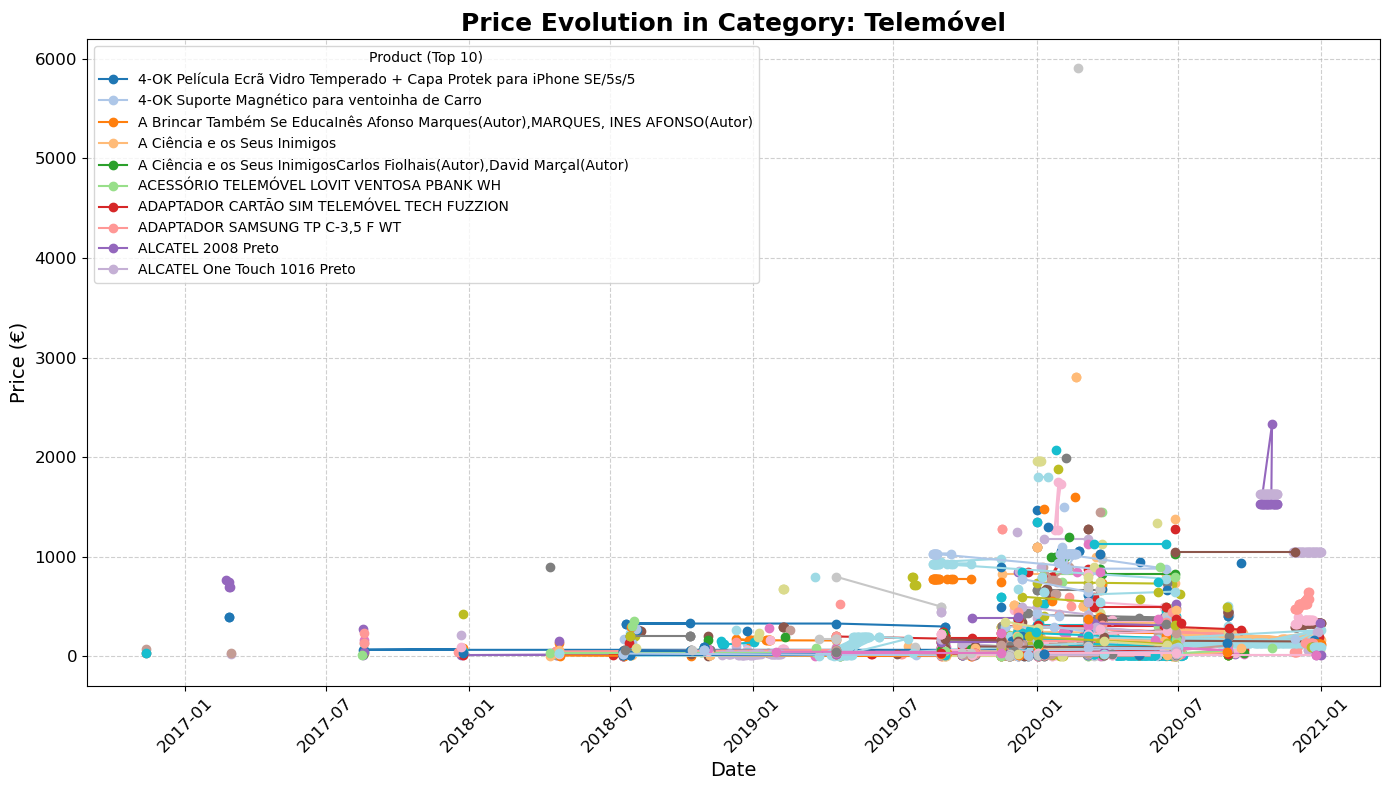

/var/folders/yk/6y9yrkbx0778n8h565f9bj4w0000gn/T/ipykernel_61845/1301377773.py:39: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("tab20")  # Improved color palette


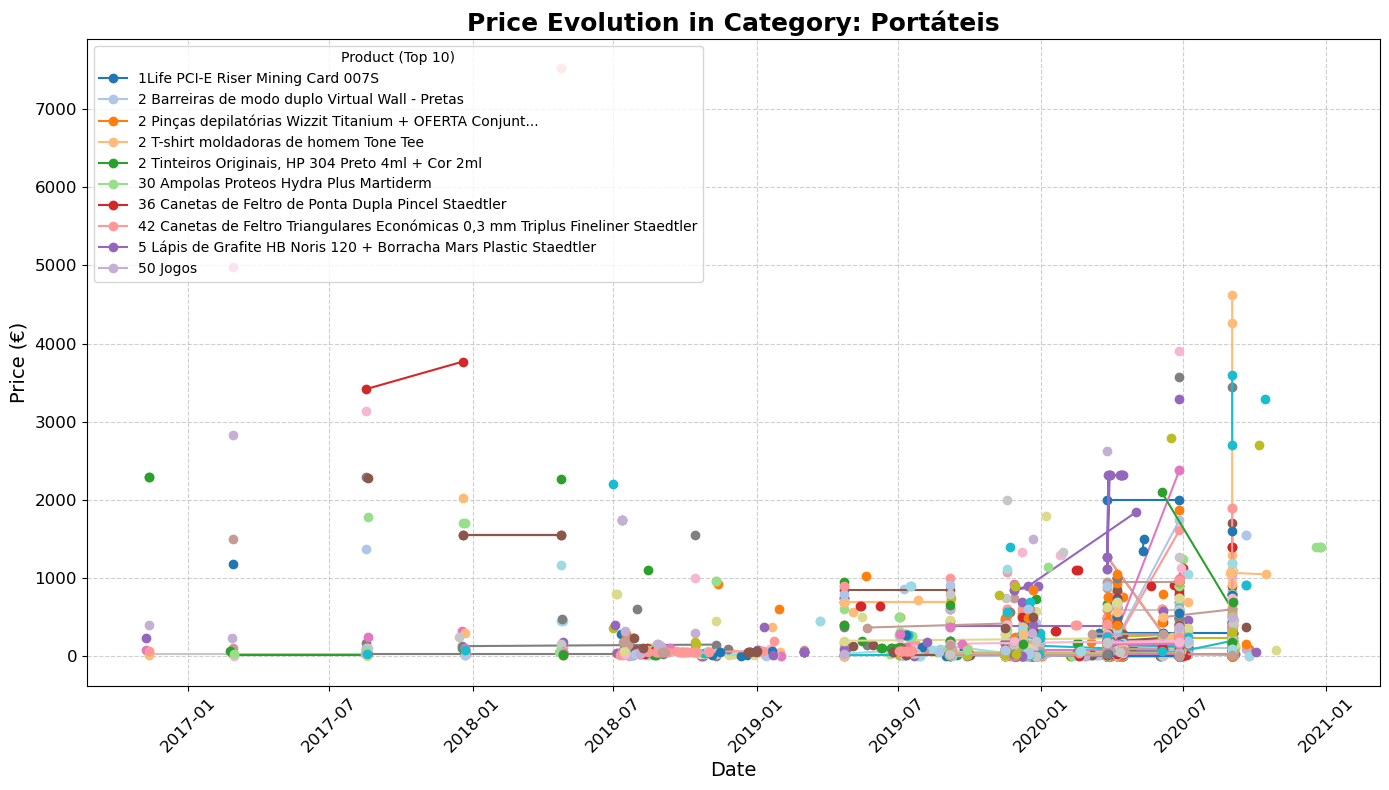

/var/folders/yk/6y9yrkbx0778n8h565f9bj4w0000gn/T/ipykernel_61845/1301377773.py:39: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("tab20")  # Improved color palette


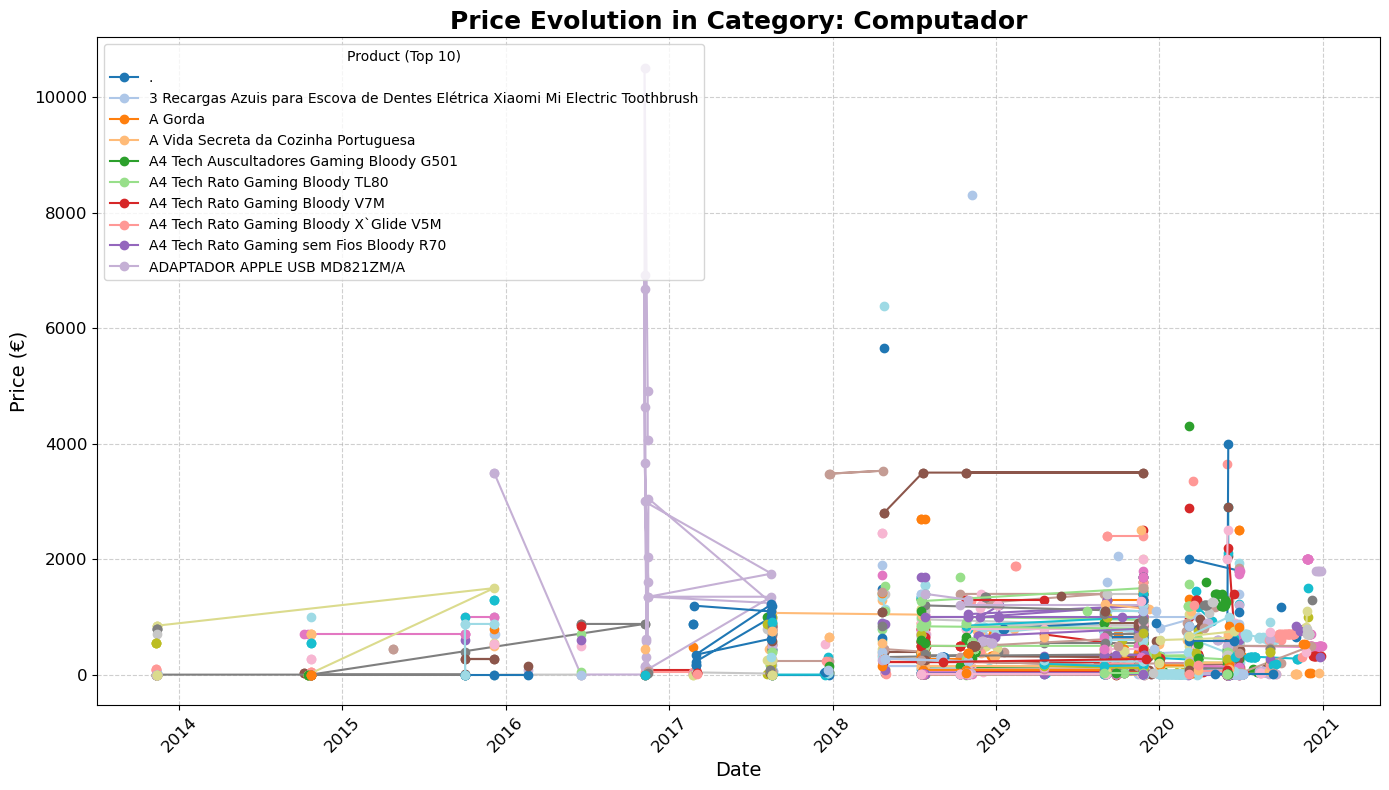

/var/folders/yk/6y9yrkbx0778n8h565f9bj4w0000gn/T/ipykernel_61845/1301377773.py:39: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("tab20")  # Improved color palette


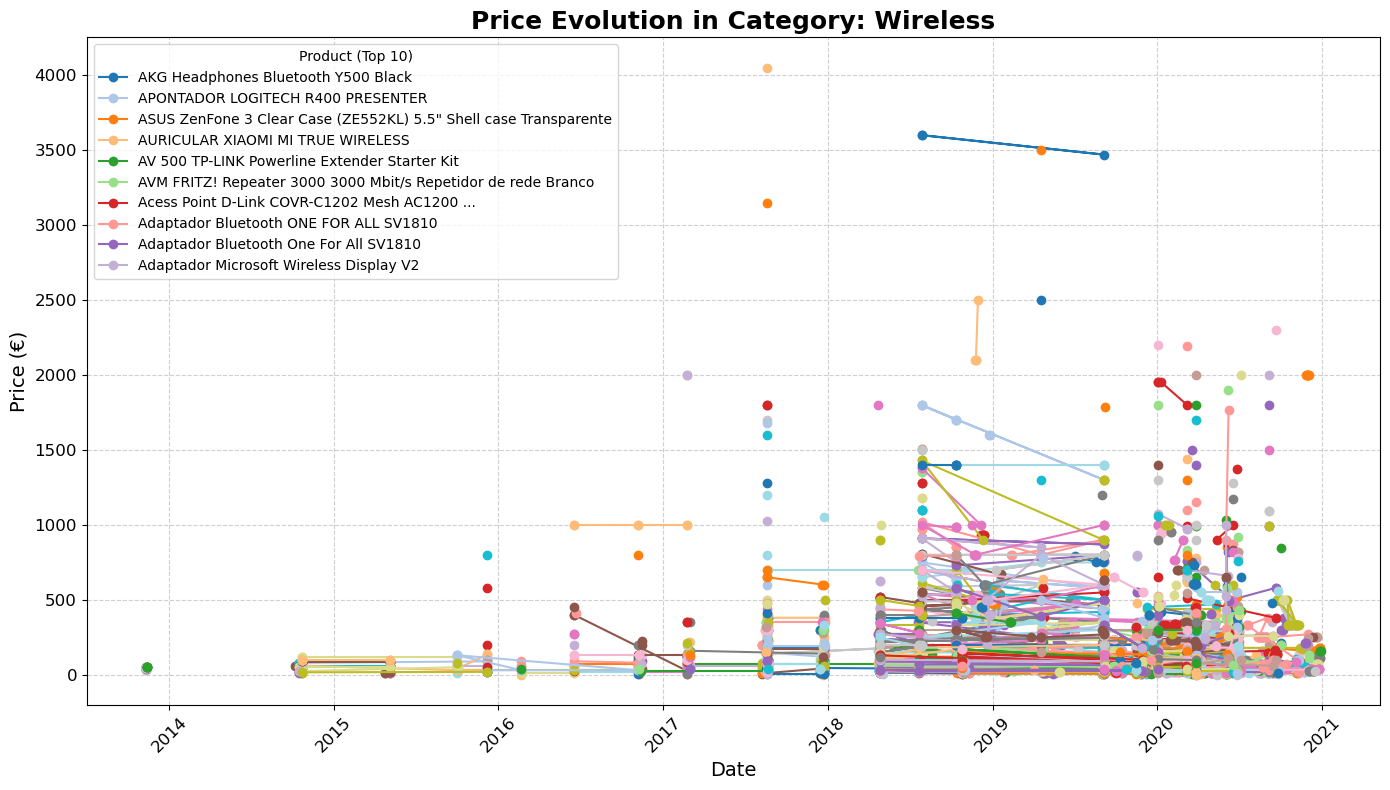

/var/folders/yk/6y9yrkbx0778n8h565f9bj4w0000gn/T/ipykernel_61845/1301377773.py:39: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("tab20")  # Improved color palette


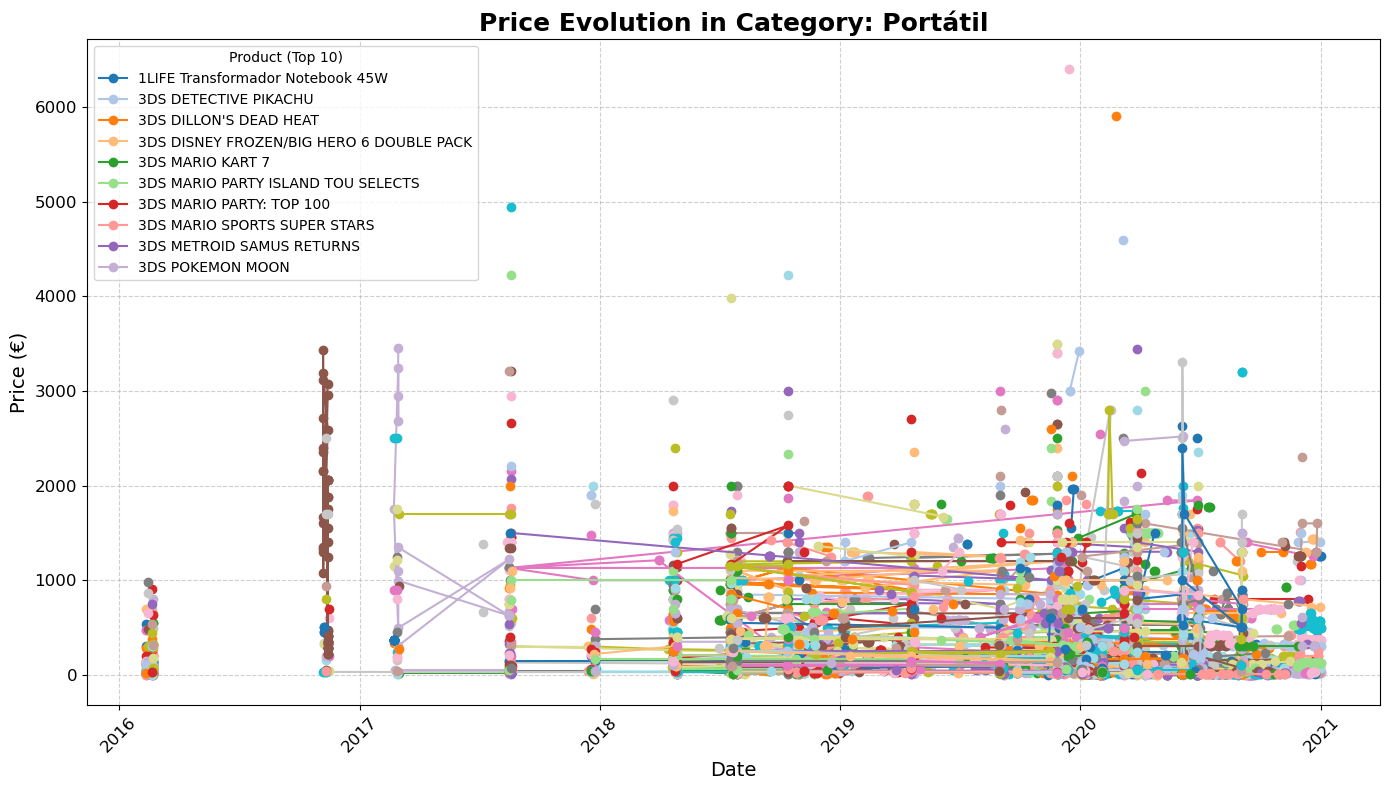

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.cm import get_cmap
from datetime import datetime


def extract_data_from_file(directory):
    """
    Reads CSV files in the given directory and organizes product data by category.
    :param directory (str): Path to the directory containing CSV files.
    :return: A dictionary where keys are categories and values are DataFrames containing the respective product data.
    """

    category_dfs = {}

    # Process each CSV file in the directory
    for file_name in os.listdir(directory):
        if file_name.startswith('scraped_') and file_name.endswith('.csv'):
            file_path = os.path.join(directory, file_name)

            # Read the CSV into a DataFrame
            df = pd.read_csv(file_path)
            
            # Ensure the necessary columns exist
            if {'category', 'price', 'timestamp', 'title'}.issubset(df.columns):
                # Convert timestamp to datetime
                df['timestamp'] = pd.to_datetime(df['timestamp'], format='%Y%m%d%H%M%S')
                
                # Group by category and append to the respective DataFrame
                for category, group in df.groupby('category'):
                    if category not in category_dfs:
                        category_dfs[category] = group
                    else:
                        category_dfs[category] = pd.concat([category_dfs[category], group])

    return category_dfs

def make_graphic_category_detailed(category_dfs):
    """
    Generates detailed line plots showing price evolution over time for each category.
    :param category_dfs (dict): A dictionary where keys are categories and values are DataFrames.
    """
    
    # Plot price evolution for each category
    for category, category_df in category_dfs.items():
        plt.figure(figsize=(14, 8))
        cmap = get_cmap("tab20")  # Improved color palette
        unique_titles = category_df['title'].unique()
        
        for i, (title, group) in enumerate(category_df.groupby('title')):
            color = cmap(i % 20)  # Cycle through 20 colors
            plt.plot(group['timestamp'], group['price'], marker='o', label=title, color=color, linewidth=1.5)
        
        # Customize the plot
        plt.title(f"Price Evolution in Category: {category}", fontsize=18, fontweight='bold')
        plt.xlabel("Date", fontsize=14)
        plt.ylabel("Price (€)", fontsize=14)
        plt.xticks(rotation=45, fontsize=12)
        plt.yticks(fontsize=12)
        plt.grid(True, linestyle='--', alpha=0.6)
        
        # Limit legend to the top 10 products for clarity
        handles, labels = plt.gca().get_legend_handles_labels()
        plt.legend(handles[:10], labels[:10], title="Product (Top 10)", fontsize=10, loc='upper left', frameon=True)
        
        plt.tight_layout()
        plt.savefig(f"Plots/{category}_price_evolution_detailed.png")  # Save improved graph
        plt.show()

    return  # Return the DataFrame dictionary for further use

def main():
    category_dfs = extract_data_from_file('./Scraped_Results')
    make_graphic_category_detailed(category_dfs)

if __name__ == "__main__":
    main()  # Run the main function

## Additional Data Cleaning 

After analysing the data from the visualizations, we saw that the data had to be even more cleaned because for some categories the products retrived are not in conformaty with the category it self.

In [27]:
import pandas as pd
import os


def clean_data(df, irrelevant_keywords):
    """
    Removes rows from the DataFrame where the title contains any of the irrelevant keywords.
    :param df: The DataFrame to clean.
    :param irrelevant_keywords: List of keywords to filter out.
    :return: Cleaned DataFrame.
    """
    # Remove rows containing irrelevant Portuguese keywords
    cleaned_df = df[~df['title'].str.lower().str.contains('|'.join(irrelevant_keywords), case=False, na=False)]
    return cleaned_df


def remove_unrelated_products(directory):
    """
    Removes unrelated products from the scraped data based on keywords.
    :param directory: The directory containing the scraped CSV files
    """

    # Define irrelevant keywords for each category
    irrelevant_keywords_telemovel_smartphone = [
        "google chromecast", "auriculares", "estabilizador", "auscultadores", "capa", "watch", "ps4", "tv", "bluetooth", "água"
        "smartwatch", "pulseira", "carregador", "cabo", "fone", "earbuds", "earphone", "earphones", "headset", "canon"
        "powerbank", "bateria", "tripé", "microfone", "drone", "impressora", "scanner", "relógio", "gira", "powerbank", "televisor",
        "multifuncional", "capa", "bolsa", "teclado", "rato", "mouse", "monitor", "drone", "máquina", "soundbar", "home",
        "coluna", "gps", "tablet", "smartband", "leitor", "câmera", "câmara", "tripé", "consola", "impressora", 
        "cabelo", "jogo", "suporte", "switch", "limpeza", "película", "pelicula", "book", "cartão micro", "cartão de memória",
        "cd", "antena", "apresentador", "tapete", "filtros", "pc", "calculadora", "centrifugadora", "webcam", "wireless", "placa",
        "ar condicionado", "microondas", "smart tv", "elétrica", "tv", "cartão", "óculos", "centro dentário", "varinha", "urbanglide", "maxcom classic", "brother rolo", "robot", "disco", "ferro", "micro-ondas"
        "recetor", "tinteiro", "faca", "comando", "adaptor", "adaptador", "estação meteorológica", "torradeira", "mochila", "picadora", "correia", "termo", "filtro", "protetor de ecrã", "brother", "saca", "fotográfico",
        "caneta", "dji", "transmissor", "rádio", "tp-link", "óleo", "dvd", "cd", "blu-ray", "fogão", "caldeira", "bracelete", "hotpoint", "hoverboard", "pen", "garmin", "mãos-livres", "mp4", "base de ventilação",
        "monopé", "auricular", "usb", "selfie", "discos", "massa térmica", "livro", "aquecedor", "elétrico", "cinto", "balança", "caixa", "forno", "emissor", "portátil", "braçadeira", "science4you", "aspirador", "frigorífico", "objetiva"
    ]

    irrelevant_keywords_computador_portatil = [
        "trotinete", "hoverboard", "gira-discos", "coluna", "smartwatch", "carregador", "cabo", "cable", "fone", "auricular", "headset", "volante", "auscultadores", "mcafee", "gravador", "nikon", "canon", "fujifilm", "sony", "panasonic", "tescoma", "kingston", "sandisk",
        "earbuds", "earphone", "earphones", "smartband", "leitor", "powerbank", "bateria", "câmera", "câmara", "tripé", "microfone", "suporte tv", "disco interno", "pen", "joystick", "secador", "mesa digitalizadora", "3ds", "tomtom", "ps4", "ps5", "candeeiro", "ebook",
        "drone", "impressora", "scanner", "multifuncional", "capa", "bolsa", "teclado", "rato", "mouse", "monitor", "adaptador", "bracelete", "disco externo", "mochila", "gps", "webcam", "xbox", "playstation", "ferro", "eléctrico", "forno", "varinha mágica",
        "comando", "consola", "smartphone", "telemóvel", "telemovel", "tv", "televisão", "televisao", "televisor", "impressora", "scanner", "multifuncional", "kaspersky", "canon multifunções", "keyinvoice", "grelhador", "tinteiro", "ereader", "book"
        "microsoft office", "hub", "ups", "apresentador", "pasta", "docking station", "google chromecast", "mala", "toalhetes", "almofada", "amplificador", "dj control", "jogo", "samsonite", "trolley", "cabo de alimentação", "bluetooth", "despertador", "compacta samsung",
        "áudio", "cabo de rede", "cabo de alimentação", "cabo de dados", "cabo de extensão", "cabo de rede", "cabo de segurança", "cabo de sinal", "cabo de vídeo", "cabo hdmi", "cabo usb", "cabo vga", "cabo óptico", "máquina secar roupa", "projetor",
        "auscultador", "nintendo switch", "altifalante", "altifalantes", "suporte", "suportes", "sistema", "router", "fogão", "placa elétrica", "calculadora", "mp4", "máquina fotográfica", "objetiva", "wireless", "máquina", "wifi", "canon", "robot", "ipod",
        "aquecedor", "ar condicionado", "microondas", "forno", "torradeira", "máquina de café", "máquina de lavar", "máquina de secar", "máquina de lavar loiça", "máquina de barbear", "máquina de cortar cabelo", "máquina de costura", "usb", "disco rígido", "protector",
        "rádio", "rotuladora", "eléctrica", "base de ventilação", "escova", "dvd", "cd", "blu-ray", "fotográfico", "fotográfica", "smart tv", "tv box", "tv led", "tv oled", "tv qled", "tv uhd", "tv ultra hd", "tv 4k", "tv 8k", "tv hd", "tv full hd", "caneta", "objectiva",
        "aspirador", "placa", "ventoinha", "vaporizador", "termoventilador", "jogo", "soundbar", "bisnaga", "repetidor", "tp-link", "correia", "base de refrigeração", "radio", "ps4", "mp3", "phones", "printer", "antena", "extensor", "nintendo", "cadeira", "papel", "pilhas",
        "porta-documentos", "tapete", "maleta", "science4you", "roll run", "patrulha pata", "chromecast", "comboio", "icamara", "security", "limpa", "subwoofer", "earpods", "hdmi", "limpeza", "dj", "elétrica", "go pro", "extended remote", "oferta", "cartÃ£o de memÃ³ria"
    ]

    irrelevant_keywords_computador_wireless = [
        "fotográfica", "smartphone", "iphone", "monitor", "smart tv", "cellular line", "watch", "hercules controlador", "consola",
        "lâmpada", "multifunções", "câmera", "câmara", "impressora", "carregador", "película", "pelicula", "cabo", "book", "tv", "canon",
        "tapete", "calculadora", "televisor"
    ]

    
    for file_name in os.listdir(directory):
        if file_name.startswith('scraped_') and file_name.endswith('.csv'):
            file_path = os.path.join(directory, file_name)
            print(f"Processing file: {file_path}")
            df = pd.read_csv(file_path)

            if 'category' in df.columns:
                category = df['category'].iloc[0]
                if category == 'Telemóvel' or category == 'Smartphone':
                    cleaned_df = clean_data(df, irrelevant_keywords_telemovel_smartphone)
                elif category == 'Portátil' or category == 'Portáteis' or category == 'Computador' or category == 'Computadores':
                    cleaned_df = clean_data(df, irrelevant_keywords_computador_portatil)
                elif category == 'Wireless':
                    cleaned_df = clean_data(df, irrelevant_keywords_computador_wireless)
                else:
                    print(f"Category '{category}' not recognized. Skipping file.")
                    continue

            # Save the cleaned data back to the file
            cleaned_df.to_csv(f"./Final/{file_name}", index=False)
            print(f"Filtered data saved to ./Final/{file_name}")

def main():
    remove_unrelated_products('./Scraped_Results2')

if __name__ == "__main__":
    main()  # Run the main function

Processing file: ./Scraped_Results2/scraped_www_worten_pt_Computador.csv
Filtered data saved to ./Final/scraped_www_worten_pt_Computador.csv
Processing file: ./Scraped_Results2/scraped_www_worten_pt_Computadores.csv
Filtered data saved to ./Final/scraped_www_worten_pt_Computadores.csv
Processing file: ./Scraped_Results2/scraped_www_worten_pt_Portáteis.csv
Filtered data saved to ./Final/scraped_www_worten_pt_Portáteis.csv
Processing file: ./Scraped_Results2/scraped_www_worten_pt_Portátil.csv
Filtered data saved to ./Final/scraped_www_worten_pt_Portátil.csv
Processing file: ./Scraped_Results2/scraped_www_worten_pt_Smartphone.csv
Filtered data saved to ./Final/scraped_www_worten_pt_Smartphone.csv
Processing file: ./Scraped_Results2/scraped_www_worten_pt_Telemóvel.csv
Filtered data saved to ./Final/scraped_www_worten_pt_Telemóvel.csv
Processing file: ./Scraped_Results2/scraped_www_worten_pt_Wireless.csv
Filtered data saved to ./Final/scraped_www_worten_pt_Wireless.csv


## Visualizations 
See the diferance on number of rows after

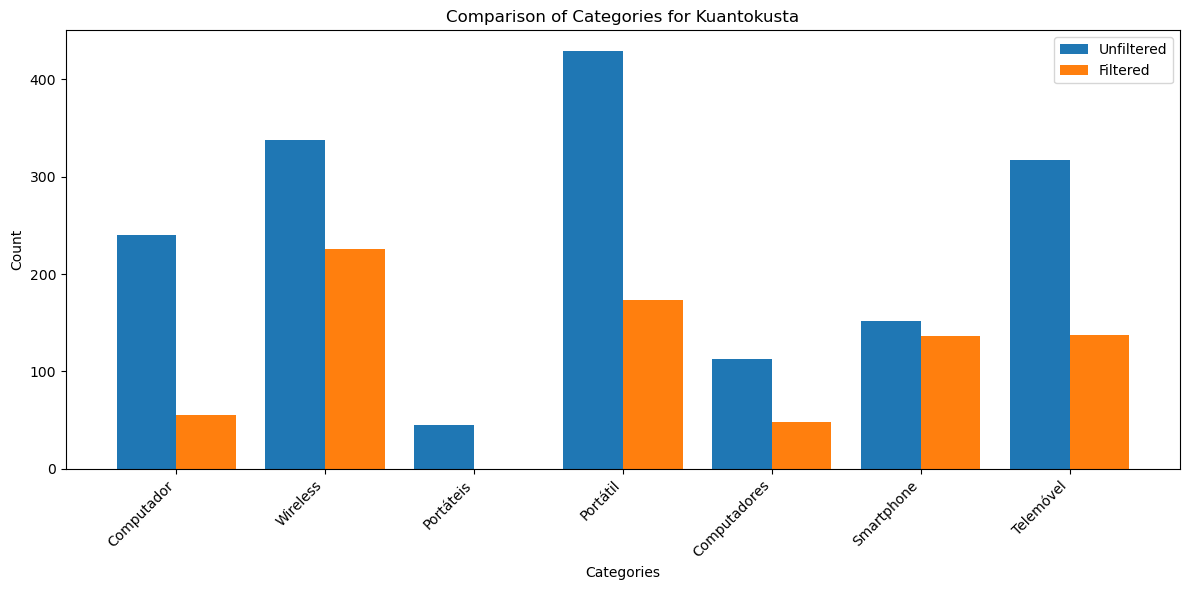

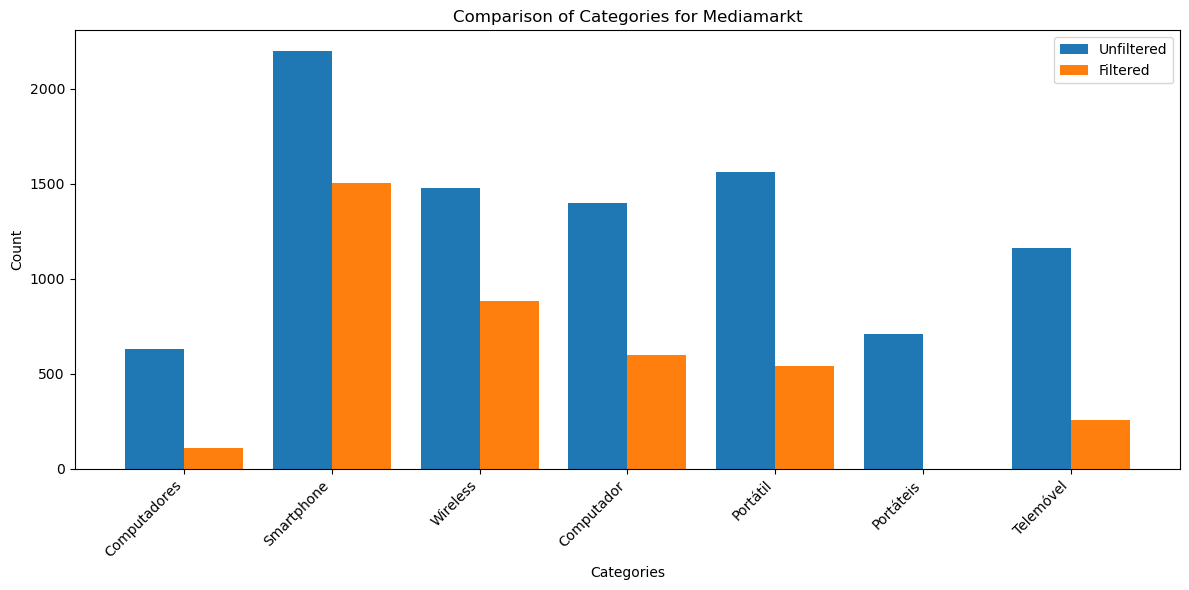

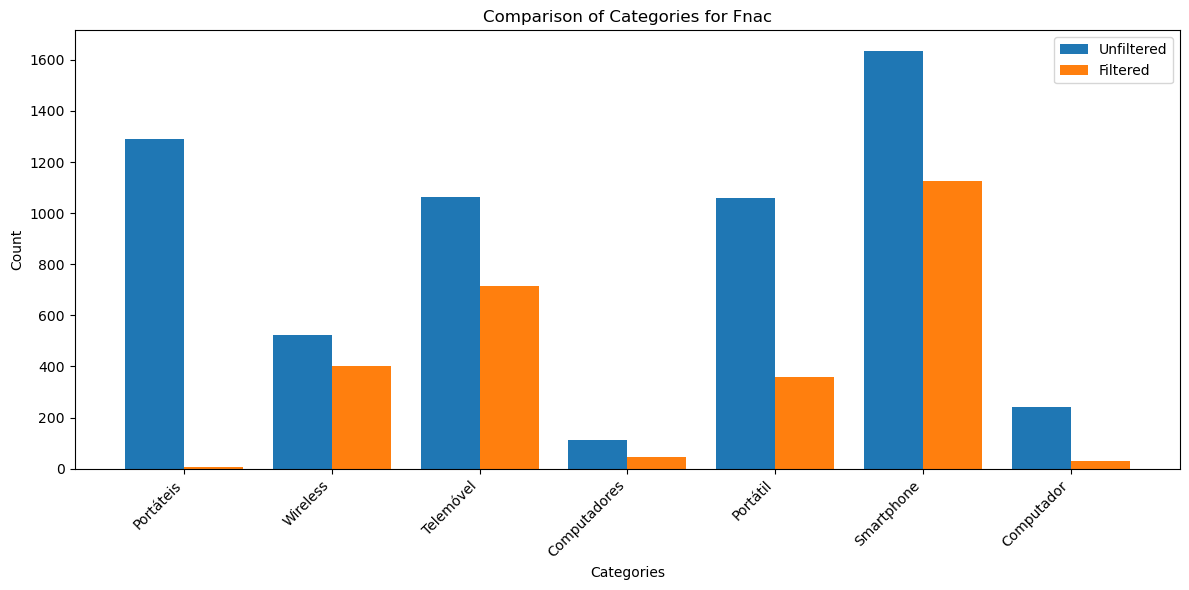

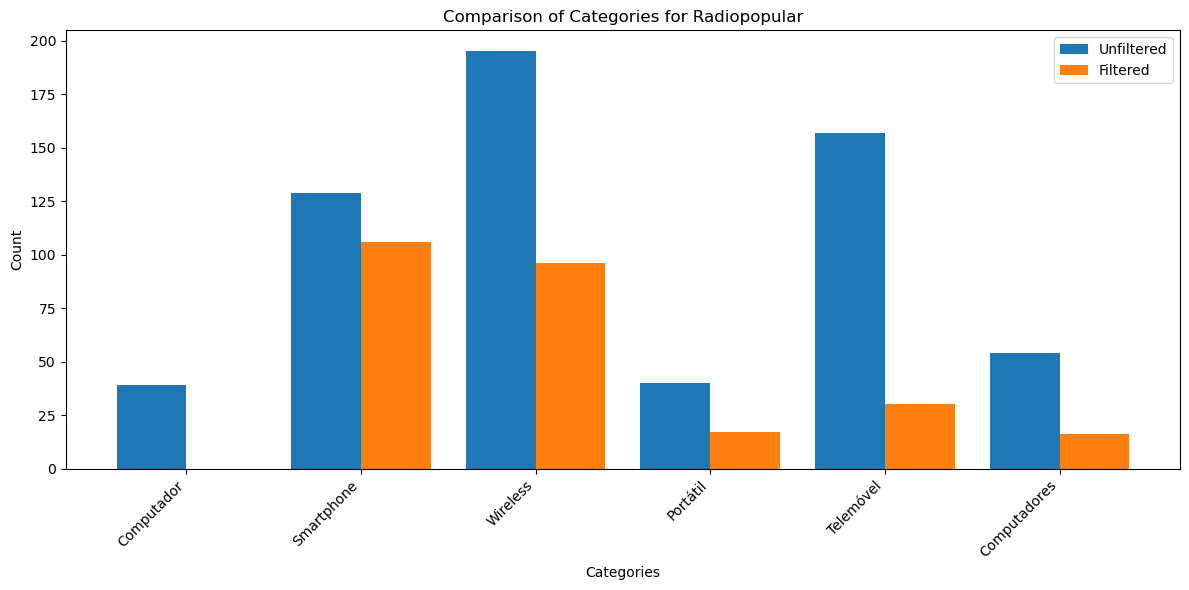

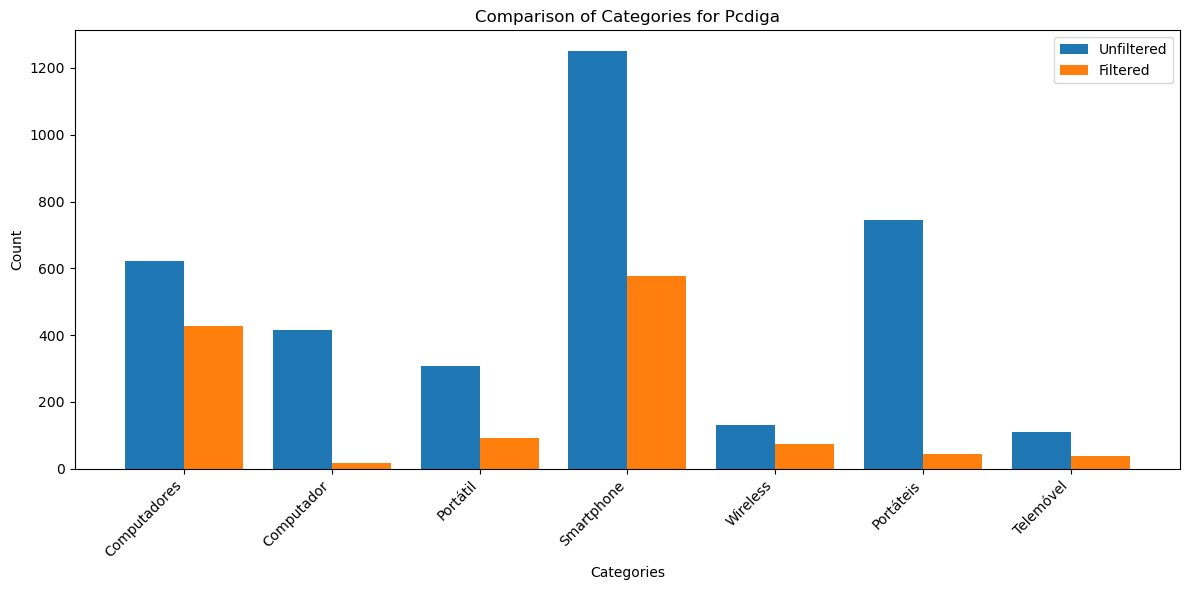

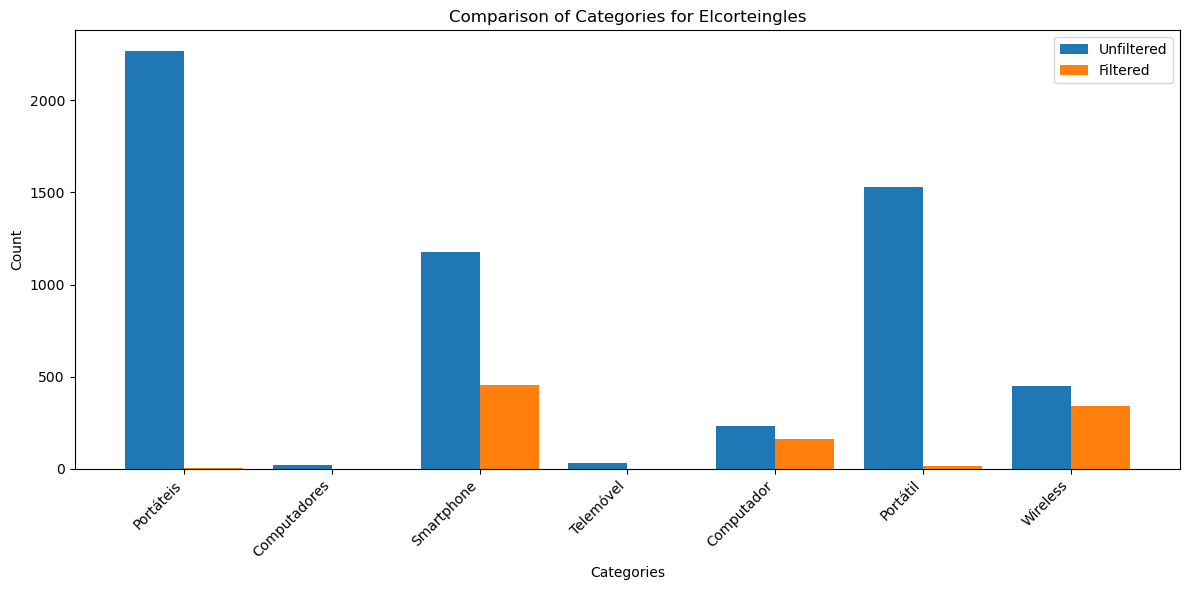

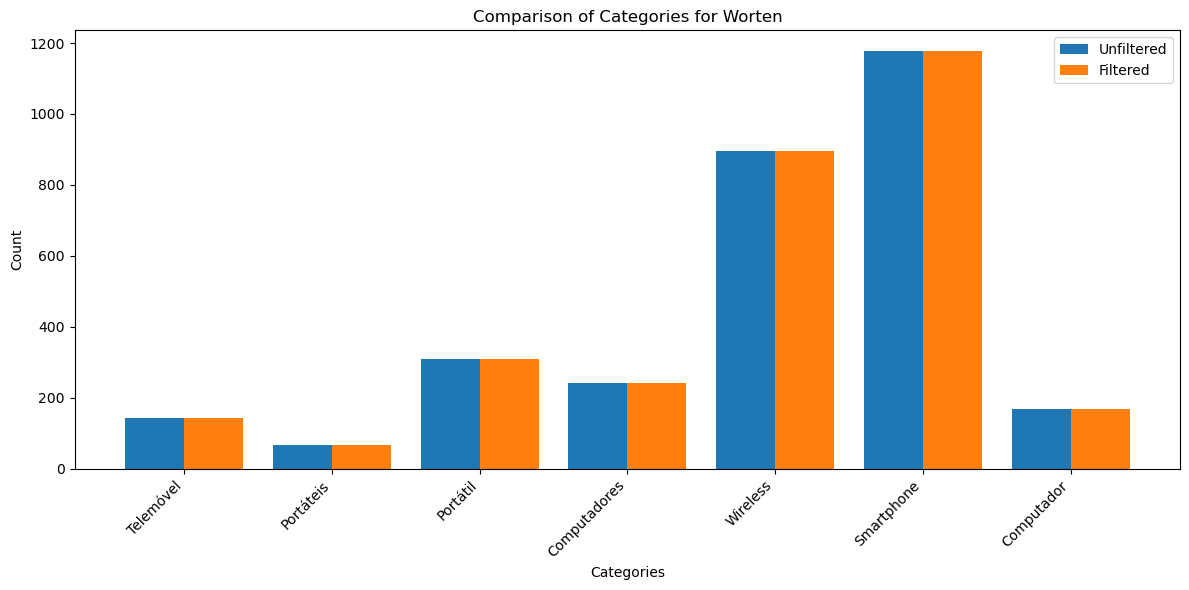

In [7]:
import os
import pandas as pd
import matplotlib.pyplot as plt

def extract_website_name(file_name):
    """
    Extract the website name from the file name.
    Assumes file names follow the pattern: 'scraped_<website>_<category>.csv'.
    """

    possible_name = file_name.split("_")[1]

    if possible_name == 'www':
        return file_name.split("_")[2]
    else:
        return possible_name

def make_graphic_category_website(unfilter_data_path, filtered_data_path):
    """
    Compare data in files with the same names from two directories and generate a comparison graph.

    :param unfilter_data_path: Path to the directory with unfiltered data.
    :param filtered_data_path: Path to the directory with filtered data.
    """
    # Get the list of files in both directories
    unfiltered_files = sorted(os.listdir(unfilter_data_path))
    filtered_files = sorted(os.listdir(filtered_data_path))

    # Ensure only matching files are compared
    common_files = set(unfiltered_files).intersection(filtered_files)
    if not common_files:
        print("No matching files found between the directories.")
        return

    # Group data by website
    website_data = {}

    for file_name in common_files:
        
        # Extract website name from file name
        website_name = extract_website_name(file_name)

        # Read the files into pandas DataFrames
        unfiltered_file_path = os.path.join(unfilter_data_path, file_name)
        filtered_file_path = os.path.join(filtered_data_path, file_name)

        # Load data
        unfiltered_df = pd.read_csv(unfiltered_file_path, delimiter=",")
        filtered_df = pd.read_csv(filtered_file_path)

        # Count categories in both files
        unfiltered_category_counts = unfiltered_df["category"].value_counts()
        filtered_category_counts = filtered_df["category"].value_counts()

        # Normalize to ensure same category list
        all_categories = set(unfiltered_category_counts.index).union(filtered_category_counts.index)

        # Initialize website data if not already present
        if website_name not in website_data:
            website_data[website_name] = {"Unfiltered": [], "Filtered": [], "Category": []}

        for category in all_categories:
            website_data[website_name]["Unfiltered"].append(unfiltered_category_counts.get(category, 0))
            website_data[website_name]["Filtered"].append(filtered_category_counts.get(category, 0))
            website_data[website_name]["Category"].append(category)


    # Create bar charts for each website
    for website_name, data in website_data.items():
        categories = data["Category"]
        unfiltered_values = data["Unfiltered"]
        filtered_values = data["Filtered"]

        x = range(len(categories))  # Position of bars on the x-axis

        plt.figure(figsize=(12, 6))
        plt.bar(x, unfiltered_values, width=0.4, label="Unfiltered", align="center")
        plt.bar([i + 0.4 for i in x], filtered_values, width=0.4, label="Filtered", align="center")
        plt.xticks([i + 0.2 for i in x], categories, rotation=45, ha="right")
        plt.xlabel("Categories")
        plt.ylabel("Count")
        plt.title(f"Comparison of Categories for {website_name.capitalize()}")
        plt.legend()
        plt.tight_layout()
        plt.show()

def main():
    unfilter_data_path = './Scraped_Results'
    filtered_data_path = './Final'
    make_graphic_category_website(unfilter_data_path, filtered_data_path)

if __name__ == "__main__":
    main()  # Run the main function

### Predict Prices

Detecting anomalies for product: HP Pavilion 690-0012NP Desktop Gaming i7 8gb Ram 256GB SSD GeForce GTX 4GB
Detecting anomalies for product: Apple Mac Pro MD878PO/A 6-Core Xeon E5 16GB RAM 256GB SSD 2xAMD FirePro D500 3GB


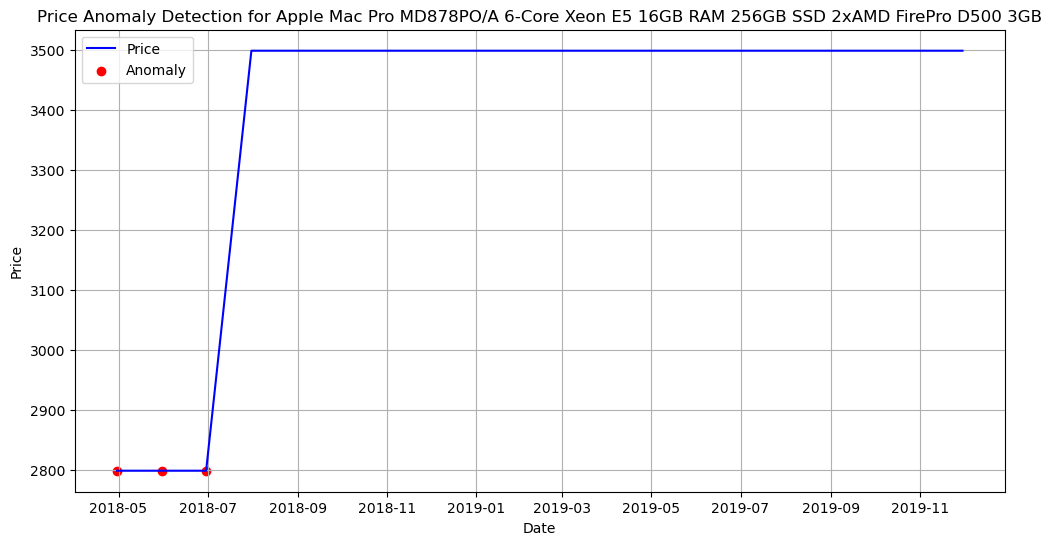

Anomalies detected for product: Apple Mac Pro MD878PO/A 6-Core Xeon E5 16GB RAM 256GB SSD 2xAMD FirePro D500 3GB
             price  anomaly_score
timestamp                        
2018-04-30  2799.2      -0.286097
2018-05-31  2799.2      -0.286097
2018-06-30  2799.2      -0.286097
Detecting anomalies for product: Acer Aspire XC-330 AMD 8GB RAM 1TB HDD Geforce 2GB
Detecting anomalies for product: Lenovo IdeaCentre 720-18APR-131 PC Desktop | AMD RYZEN 5-2400 | 8GB RAM | 2TB HDD
Detecting anomalies for product: Lenovo 310S-08ASR-087 PC Desktop | AMD A4-9125 | 4GB RAM | 1TB HDD


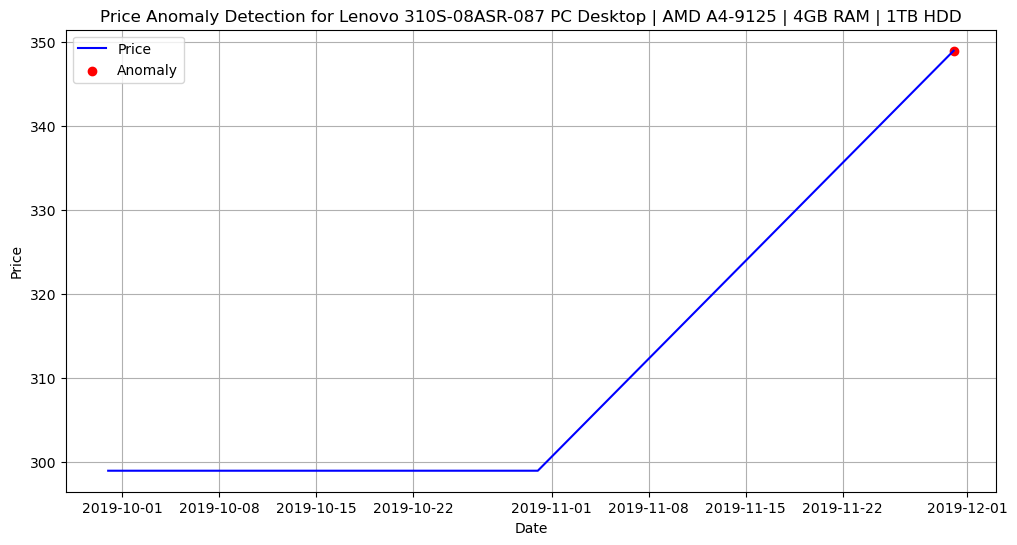

Anomalies detected for product: Lenovo 310S-08ASR-087 PC Desktop | AMD A4-9125 | 4GB RAM | 1TB HDD
            price  anomaly_score
timestamp                       
2019-11-30  349.0      -0.196803
Detecting anomalies for product: Acer Aspire AXC-885 Core i5 8GB RAM 1TB HDD Geforce 2GB


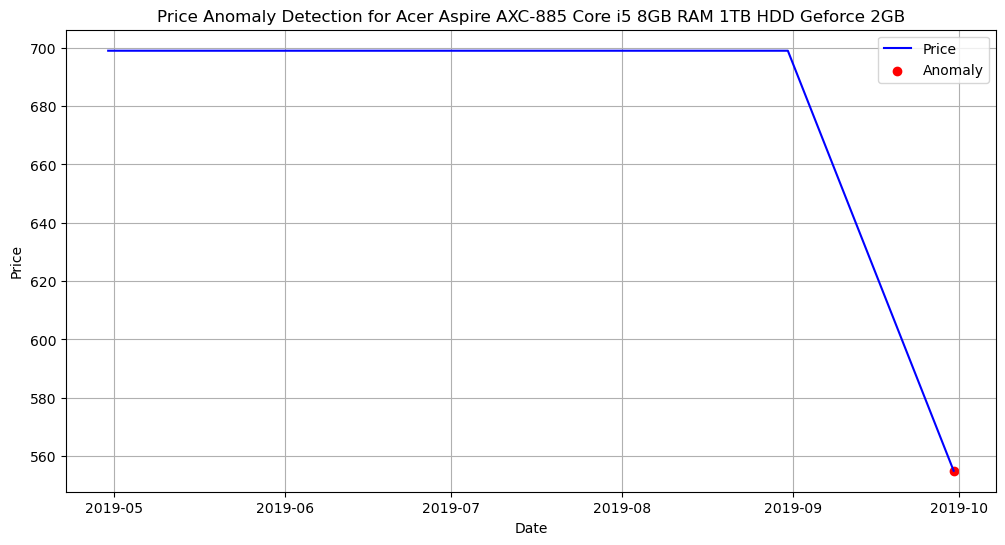

Anomalies detected for product: Acer Aspire AXC-885 Core i5 8GB RAM 1TB HDD Geforce 2GB
            price  anomaly_score
timestamp                       
2019-09-30  555.0      -0.347519
Detecting anomalies for product: HP 260-a106np Slimline AMD E2-7110 4GB RAM 500GB Disco


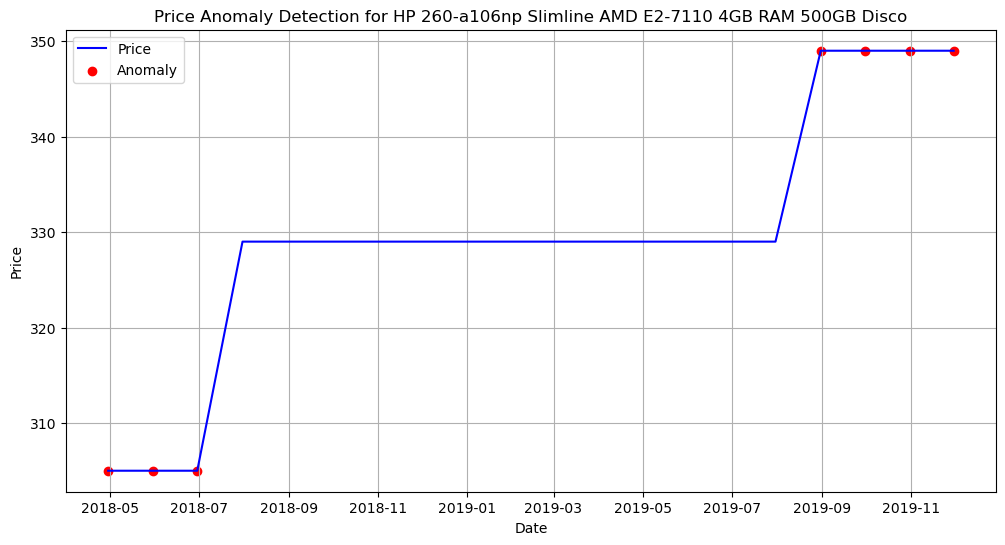

Anomalies detected for product: HP 260-a106np Slimline AMD E2-7110 4GB RAM 500GB Disco
            price  anomaly_score
timestamp                       
2018-04-30  305.0      -0.274615
2018-05-31  305.0      -0.274615
2018-06-30  305.0      -0.274615
2019-08-31  349.0      -0.198935
2019-09-30  349.0      -0.198935
2019-10-31  349.0      -0.198935
2019-11-30  349.0      -0.198935


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest

def filter_products_with_minimum_rows(data, min_rows=4):
    """
    Filter products that have at least a minimum number of rows.
    """
    product_counts = data["title"].value_counts()
    valid_products = product_counts[product_counts >= min_rows].index
    filtered_data = data[data["title"].isin(valid_products)]
    return filtered_data

def detect_price_anomalies(data, product_name):
    """
    Detect unusual price changes for a given product using Isolation Forest.
    """
    # Filter data for the specified product
    product_data = data[data["title"] == product_name][["timestamp", "price"]]
    
    
    if product_data.empty:
        return None

    # Prepare data
    product_data["timestamp"] = pd.to_datetime(product_data["timestamp"], format="%Y%m%d%H%M%S")
    product_data = product_data.set_index("timestamp")
    product_data = product_data.resample("ME").mean().ffill()  # Resample monthly, forward fill

    # Apply Isolation Forest for anomaly detection
    model = IsolationForest(contamination=0.4, random_state=42)
    product_data["anomaly"] = model.fit_predict(product_data[["price"]])
    product_data["anomaly_score"] = model.decision_function(product_data[["price"]])

    # Check if anomalies are detected
    anomalies = product_data[product_data["anomaly"] == -1]
    if anomalies.empty:
        return None  # No anomalies detected

    # Plot results
    plt.figure(figsize=(12, 6))
    plt.plot(product_data.index, product_data["price"], label="Price", color="blue")
    plt.scatter(
        anomalies.index,
        anomalies["price"],
        color="red",
        label="Anomaly",
    )
    plt.title(f"Price Anomaly Detection for {product_name}")
    plt.xlabel("Date")
    plt.ylabel("Price")
    plt.legend()
    plt.grid(True)
    plt.show()

    return anomalies

def main():
    # File path
    input_file = "Final/scraped_mediamarkt_pt_Computador.csv"  # Replace with your dataset file

    # Load the dataset
    data = pd.read_csv(input_file)
    data["timestamp"] = pd.to_datetime(data["timestamp"], format="%Y%m%d%H%M%S")

    # Filter products with at least 4 rows
    data = filter_products_with_minimum_rows(data, min_rows=3)
    if data.empty:
        print("No products with sufficient data.")
        return

    # Detect anomalies for products with sufficient data
    for product_name in data["title"].head(10).unique():
        print(f"Detecting anomalies for product: {product_name}")
        anomalies = detect_price_anomalies(data, product_name)
        if anomalies is not None:
            print(f"Anomalies detected for product: {product_name}")
            print(anomalies[["price", "anomaly_score"]])  # Print anomaly details

if __name__ == "__main__":
    main()

## Price Evolution per Category in every website

/tmp/ipykernel_17756/3796062880.py:38: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  all_data = pd.concat(combined_data, ignore_index=True)


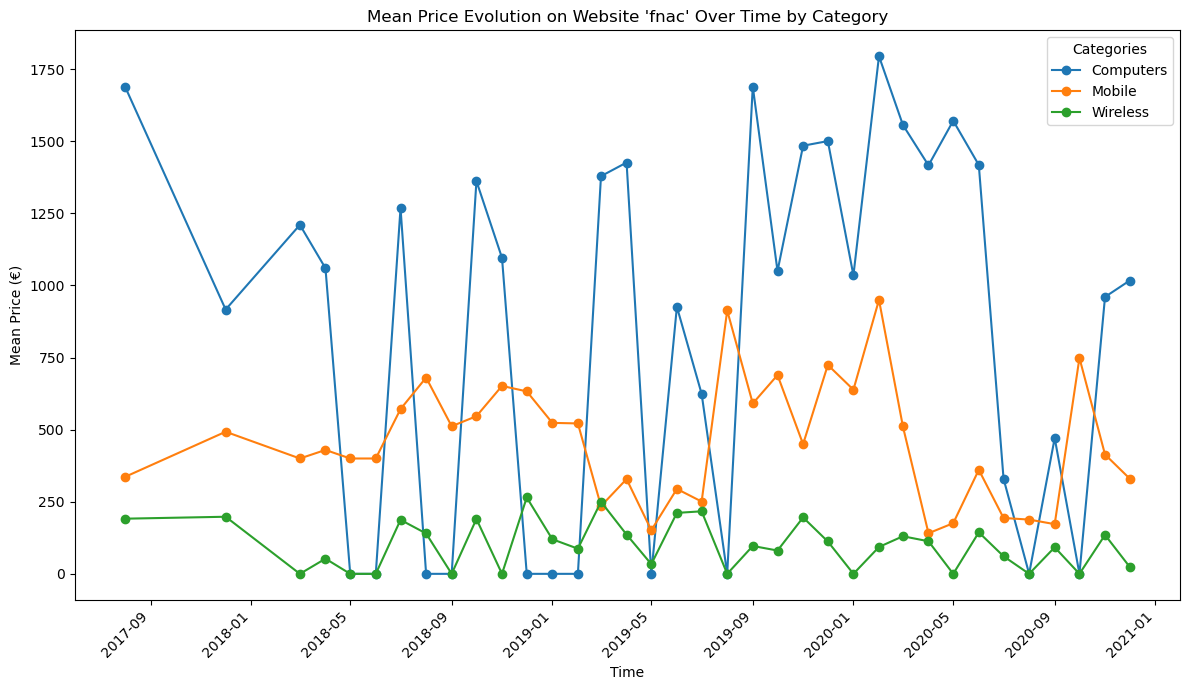

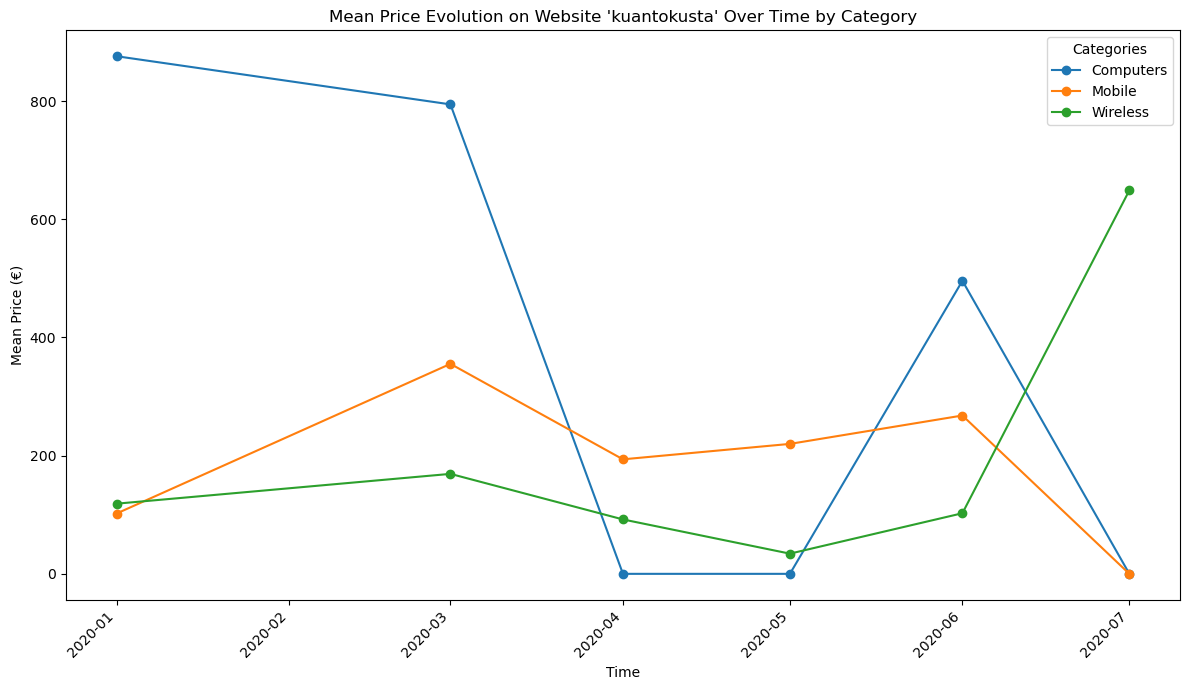

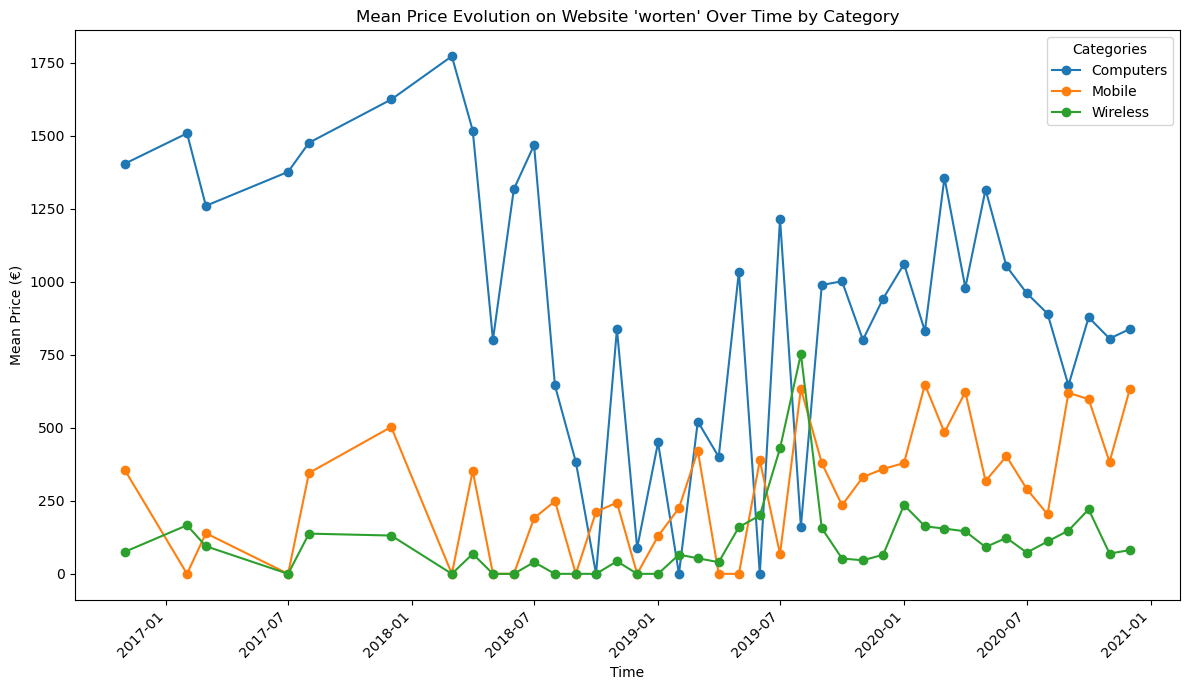

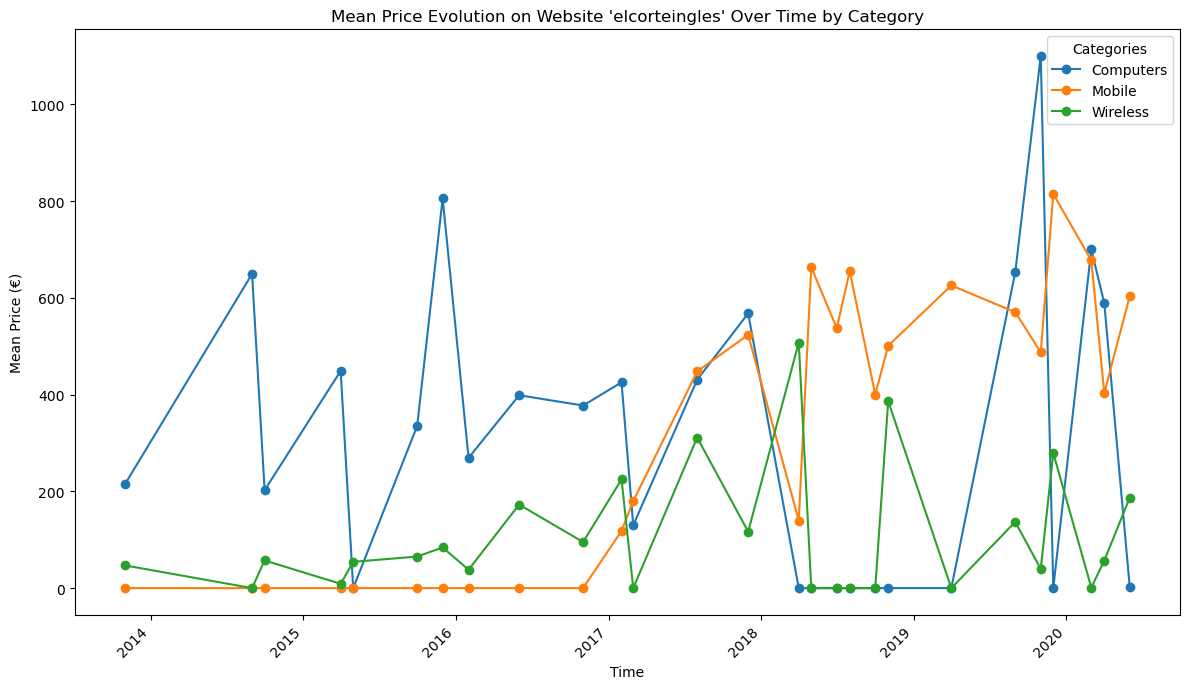

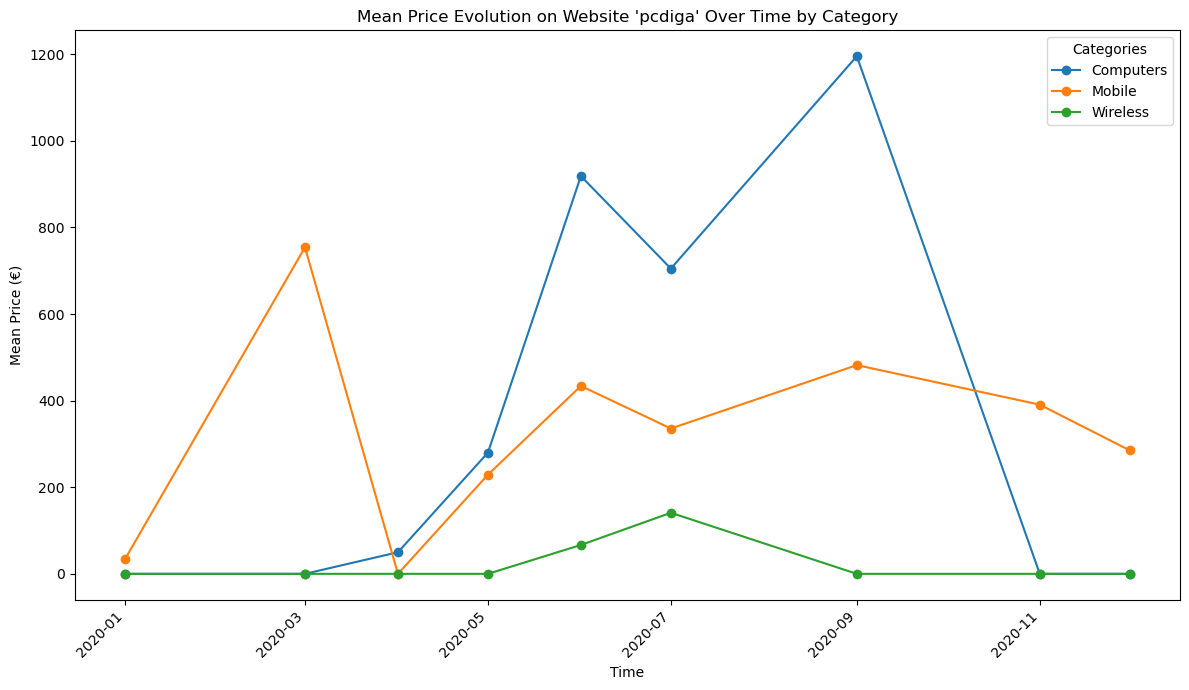

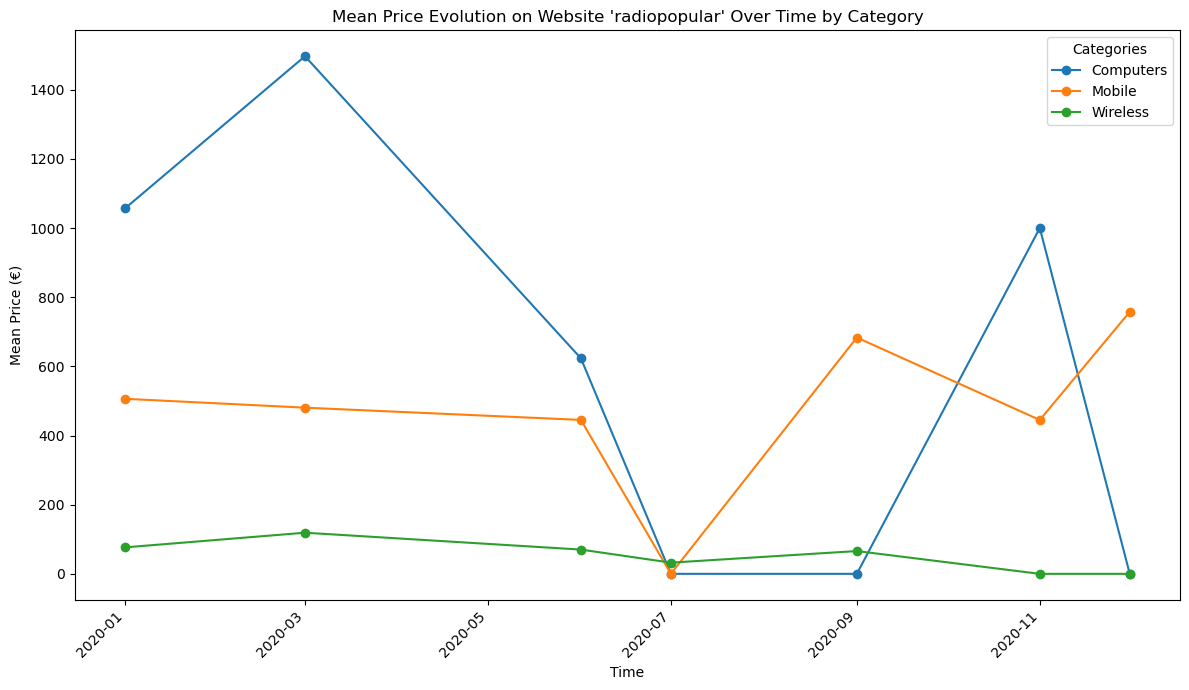

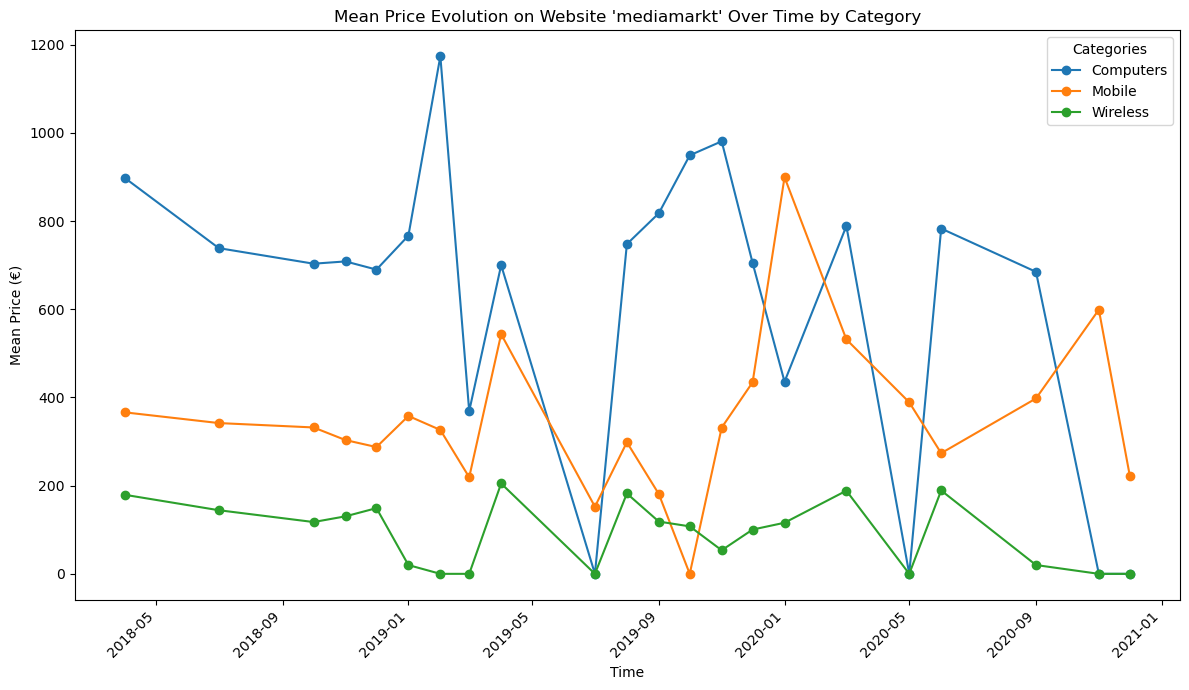

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import os

def make_mean_price_evolution_plot(path_to_files, output_folder="Plots"):
    """
    Generate plots for the evolution of mean prices for websites over time, with unified categories as lines.
    """
    os.makedirs(output_folder, exist_ok=True)  # Ensure the output folder exists

    # Category mapping to unify similar categories
    category_mapping = {
        "Computador": "Computers",
        "Computadores": "Computers",
        "Portátil": "Computers",
        "Portáteis": "Computers",
        "Telemóvel": "Mobile",
        "Smartphone": "Mobile",
        "Wireless": "Wireless"
    }

    list_of_files = os.listdir(path_to_files)

    # Combine all CSVs into one DataFrame
    combined_data = []
    for file in list_of_files:
        if file.endswith(".csv"):
            df = pd.read_csv(os.path.join(path_to_files, file))
            
            # Ensure timestamp is in datetime format
            df['timestamp'] = pd.to_datetime(df['timestamp'], format='%Y%m%d%H%M%S')
            
            # Map categories to unified names
            df['category'] = df['category'].map(category_mapping).fillna(df['category'])
            combined_data.append(df)

    # Combine all data into one DataFrame
    all_data = pd.concat(combined_data, ignore_index=True)

    # Extract the websites and create a plot for each one
    websites = all_data['website'].unique()
    for website in websites:
        website_data = all_data[all_data['website'] == website]

        # Group data by time (monthly) and category, then calculate the mean price
        website_mean_price = website_data.groupby(
            [website_data['timestamp'].dt.to_period("M"), 'category']
        )['price'].mean().unstack(fill_value=0)

        # Convert time period to datetime for plotting
        website_mean_price.index = website_mean_price.index.to_timestamp()

        # Plot the mean price evolution for the website
        plt.figure(figsize=(12, 7))
        website_mean_price.plot(kind='line', ax=plt.gca(), marker='o')

        plt.title(f"Mean Price Evolution on Website '{website}' Over Time by Category")
        plt.xlabel("Time")
        plt.ylabel("Mean Price (€)")
        plt.legend(title="Categories")
        plt.xticks(rotation=45)
        plt.tight_layout()

        plt.show()

        
        plt.close()

def main():
    path_to_files = "./Final"  # Path to your CSV files
    make_mean_price_evolution_plot(path_to_files)

if __name__ == "__main__":
    main()


# Bibliography

https://www.worten.pt 

https://www.fnac.pt

https://www.radiopopular.pt

https://mediamarkt.pt

https://www.kuantokusta.pt

https://www.elcorteingles.pt

https://www.pcdiga.pt

https://pypi.org/project/beautifulsoup4/